In [1]:
import pandas as pd

sales = pd.read_csv("retail_product_sales.csv")

sales.head()

,invoice_no,stock_code,description,quantity,invoice_date,unit_price,customer_id,country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [2]:
sales.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 527761 entries, 0 to 527760
Data columns (total 8 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   invoice_no    527761 non-null  int64  
 1   stock_code    527761 non-null  object 
 2   description   527761 non-null  object 
 3   quantity      527761 non-null  int64  
 4   invoice_date  527761 non-null  object 
 5   unit_price    527761 non-null  float64
 6   customer_id   396340 non-null  float64
 7   country       527761 non-null  object 
dtypes: float64(2), int64(2), object(4)
memory usage: 32.2+ MB


In [3]:
sales["invoice_date"] = pd.to_datetime(sales["invoice_date"])

In [4]:
sales.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 527761 entries, 0 to 527760
Data columns (total 8 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   invoice_no    527761 non-null  int64         
 1   stock_code    527761 non-null  object        
 2   description   527761 non-null  object        
 3   quantity      527761 non-null  int64         
 4   invoice_date  527761 non-null  datetime64[ns]
 5   unit_price    527761 non-null  float64       
 6   customer_id   396340 non-null  float64       
 7   country       527761 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(2), object(3)
memory usage: 32.2+ MB


In [10]:
sales["day"] = sales["invoice_date"].dt.date

sales.head()

,invoice_no,stock_code,description,quantity,invoice_date,unit_price,customer_id,country,day
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,2010-12-01
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010-12-01
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,2010-12-01
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010-12-01
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010-12-01


In [11]:
product_days = sales.groupby("stock_code")["day"].nunique()

product_days.head()

stock_code
10002     46
10080     21
10120     24
10123C     3
10124A     5
Name: day, dtype: int64

In [12]:
product_days_sorted = product_days.sort_values(ascending=False)

product_days_sorted.head(10)

stock_code
85123A    305
22423     301
84879     300
85099B    300
20725     298
21212     298
22457     297
22960     295
22197     294
22666     294
Name: day, dtype: int64

In [5]:
product_counts = sales["stock_code"].value_counts()

product_counts.head(10)

stock_code
85123A    2265
85099B    2112
22423     2017
47566     1706
20725     1595
84879     1489
22197     1426
22720     1399
21212     1370
20727     1328
Name: count, dtype: int64

In [6]:
product_sales = sales[sales["stock_code"] == "85123A"].copy()

In [7]:
product_sales.head()

,invoice_no,stock_code,description,quantity,invoice_date,unit_price,customer_id,country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
48,536373,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 09:02:00,2.55,17850.0,United Kingdom
65,536375,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 09:32:00,2.55,17850.0,United Kingdom
217,536390,85123A,WHITE HANGING HEART T-LIGHT HOLDER,64,2010-12-01 10:19:00,2.55,17511.0,United Kingdom
252,536394,85123A,WHITE HANGING HEART T-LIGHT HOLDER,32,2010-12-01 10:39:00,2.55,13408.0,United Kingdom


In [8]:
product_sales["day"] = product_sales["invoice_date"].dt.date

product_sales.head()

,invoice_no,stock_code,description,quantity,invoice_date,unit_price,customer_id,country,day
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,2010-12-01
48,536373,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 09:02:00,2.55,17850.0,United Kingdom,2010-12-01
65,536375,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 09:32:00,2.55,17850.0,United Kingdom,2010-12-01
217,536390,85123A,WHITE HANGING HEART T-LIGHT HOLDER,64,2010-12-01 10:19:00,2.55,17511.0,United Kingdom,2010-12-01
252,536394,85123A,WHITE HANGING HEART T-LIGHT HOLDER,32,2010-12-01 10:39:00,2.55,13408.0,United Kingdom,2010-12-01


In [9]:
daily_sales = product_sales.groupby("day")["quantity"].sum()

daily_sales.head()

day
2010-12-01    454
2010-12-02    309
2010-12-03     25
2010-12-05    198
2010-12-06    161
Name: quantity, dtype: int64

In [13]:
print("Πρώτη ημέρα:", daily_sales.index.min())

print("Τελευταία ημέρα:", daily_sales.index.max())

Πρώτη ημέρα: 2010-12-01
Τελευταία ημέρα: 2011-12-09


<Axes: xlabel='day'>

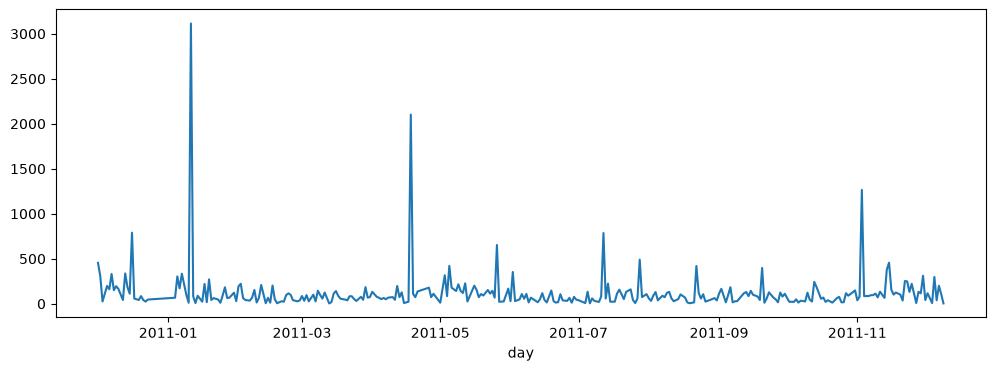

In [14]:
daily_sales.plot(figsize=(12, 4))

In [15]:
daily_sales.sort_values(ascending=False).head(5)

day
2011-01-11    3114
2011-04-18    2102
2011-11-03    1265
2010-12-16     790
2011-07-12     786
Name: quantity, dtype: int64

In [16]:
daily_sales = daily_sales.asfreq("D").fillna(0)

daily_sales.head(10)

day
2010-12-01    454.0
2010-12-02    309.0
2010-12-03     25.0
2010-12-04      0.0
2010-12-05    198.0
2010-12-06    161.0
2010-12-07    331.0
2010-12-08    151.0
2010-12-09    195.0
2010-12-10    165.0
Freq: D, Name: quantity, dtype: float64

In [17]:
train = daily_sales.iloc[:-14]

test = daily_sales.iloc[-14:]

test

day
2011-11-26      0.0
2011-11-27      8.0
2011-11-28    133.0
2011-11-29    116.0
2011-11-30    311.0
2011-12-01     41.0
2011-12-02    117.0
2011-12-03      0.0
2011-12-04      8.0
2011-12-05    298.0
2011-12-06     39.0
2011-12-07    200.0
2011-12-08    108.0
2011-12-09      4.0
Freq: D, Name: quantity, dtype: float64

In [18]:
mean_sales = train.mean()

mean_sales

np.float64(100.76944444444445)

In [19]:
mae_mean = (test - mean_sales).abs().mean()

mae_mean

np.float64(84.5)

In [21]:
%pip install statsmodels

   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   -- ------------------------------------- 0.8/11.3 MB 8.3 MB/s eta 0:00:02
   ---------------------------------------  11.3/11.3 MB 41.9 MB/s eta 0:00:01
   ---------------------------------------- 11.3/11.3 MB 32.1 MB/s  0:00:00

   ---------------------------------------- 0/6 [wrapt]
   ---------------------------------------- 0/6 [wrapt]
   ------ --------------------------------- 1/6 [patsy]
   ------ --------------------------------- 1/6 [patsy]
   ------ --------------------------------- 1/6 [patsy]
   ------ --------------------------------- 1/6 [patsy]
   ------------- -------------------------- 2/6 [narwhals]
   ------------- -------------------------- 2/6 [narwhals]
   ------------- -------------------------- 2/6 [narwhals]
   ------------- -------------------------- 2/6 [narwhals]
   ------------- -------------------------- 2/6 [narwhals]
   ------------- -------------------------- 2/6 [narwhals]
   ----


[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [24]:
from statsmodels.tsa.holtwinters import SimpleExpSmoothing

ses_model = SimpleExpSmoothing(train, initialization_method="estimated").fit()

ses_forecast = ses_model.forecast(14)

ses_forecast

2011-11-26    100.7696
2011-11-27    100.7696
2011-11-28    100.7696
2011-11-29    100.7696
2011-11-30    100.7696
2011-12-01    100.7696
2011-12-02    100.7696
2011-12-03    100.7696
2011-12-04    100.7696
2011-12-05    100.7696
2011-12-06    100.7696
2011-12-07    100.7696
2011-12-08    100.7696
2011-12-09    100.7696
Freq: D, dtype: float64

In [25]:
mae_ses = (test - ses_forecast).abs().mean()

mae_ses

np.float64(84.5)

In [26]:
ses_model.params["smoothing_level"]

np.float64(1.4901161193847656e-08)

In [27]:
last_week = train.iloc[-7:]

seasonal_naive_forecast = pd.Series(last_week.tolist() * 2, index=test.index)

seasonal_naive_forecast

day
2011-11-26      0.0
2011-11-27    101.0
2011-11-28     36.0
2011-11-29    253.0
2011-11-30    248.0
2011-12-01    131.0
2011-12-02    222.0
2011-12-03      0.0
2011-12-04    101.0
2011-12-05     36.0
2011-12-06    253.0
2011-12-07    248.0
2011-12-08    131.0
2011-12-09    222.0
Freq: D, dtype: float64

In [28]:
mae_seasonal_naive = (test - seasonal_naive_forecast).abs().mean()

mae_seasonal_naive

np.float64(103.07142857142857)

In [29]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

hw_model = ExponentialSmoothing(
    train,
    trend="add",
    seasonal="add",
    seasonal_periods=7,
    initialization_method="estimated"
).fit()

hw_forecast = hw_model.forecast(14)

hw_forecast

2011-11-26    -13.193144
2011-11-27     48.138274
2011-11-28    115.770409
2011-11-29    173.122270
2011-11-30     82.829245
2011-12-01    167.500252
2011-12-02     60.131757
2011-12-03    -13.401524
2011-12-04     47.929893
2011-12-05    115.562029
2011-12-06    172.913890
2011-12-07     82.620865
2011-12-08    167.291872
2011-12-09     59.923377
Freq: D, dtype: float64

In [30]:
mae_hw = (test - hw_forecast).abs().mean()

mae_hw

np.float64(81.53572785780645)

In [31]:
hw_forecast_zero = hw_forecast.clip(lower=0)

mae_hw_zero = (test - hw_forecast_zero).abs().mean()

mae_hw_zero

np.float64(79.63610874184916)

In [32]:
%pip install prophet

   ---------------------------------------- 0.0/12.1 MB ? eta -:--:--
   --------- ------------------------------ 2.9/12.1 MB 17.7 MB/s eta 0:00:01
   ---------------------------------------  12.1/12.1 MB 39.0 MB/s eta 0:00:01
   ---------------------------------------- 12.1/12.1 MB 30.0 MB/s  0:00:00
   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ---------------------------------------- 1.7/1.7 MB 9.4 MB/s  0:00:00

   ---------------------------------------- 0/5 [tqdm]
   ---------------------------------------- 0/5 [tqdm]
   ---------------------------------------- 0/5 [tqdm]
   ---------------------------------------- 0/5 [tqdm]
   -------- ------------------------------- 1/5 [stanio]
   ---------------- ----------------------- 2/5 [holidays]
   ---------------- ----------------------- 2/5 [holidays]
   ---------------- ----------------------- 2/5 [holidays]
   ---------------- ----------------------- 2/5 [holidays]
   ---------------- ---------------------


[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [33]:
prophet_train = pd.DataFrame()

prophet_train["ds"] = train.index

prophet_train["y"] = train.tolist()

prophet_train.head()

,ds,y
0,2010-12-01,454.0
1,2010-12-02,309.0
2,2010-12-03,25.0
3,2010-12-04,0.0
4,2010-12-05,198.0


In [34]:
from prophet import Prophet

prophet_model = Prophet().fit(prophet_train)

Importing plotly failed. Interactive plots will not work.
C:\Users\tasos\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
23:16:47 - cmdstanpy - INFO - Chain [1] start processing
23:16:47 - cmdstanpy - INFO - Chain [1] done processing


In [35]:
prophet_dates = pd.DataFrame()

prophet_dates["ds"] = test.index

prophet_result = prophet_model.predict(prophet_dates)

prophet_result[["ds", "yhat"]]

,ds,yhat
0,2011-11-26,-11.783637
1,2011-11-27,49.766386
2,2011-11-28,111.923874
3,2011-11-29,178.824244
4,2011-11-30,86.335254
5,2011-12-01,145.576202
6,2011-12-02,61.889239
7,2011-12-03,-11.935289
8,2011-12-04,49.614734
9,2011-12-05,111.772222


In [36]:
prophet_forecast = prophet_result.set_index("ds")["yhat"]

prophet_forecast_zero = prophet_forecast.clip(lower=0)

mae_prophet_zero = (test - prophet_forecast_zero).abs().mean()

mae_prophet_zero

np.float64(77.60800730513087)

<Axes: xlabel='day'>

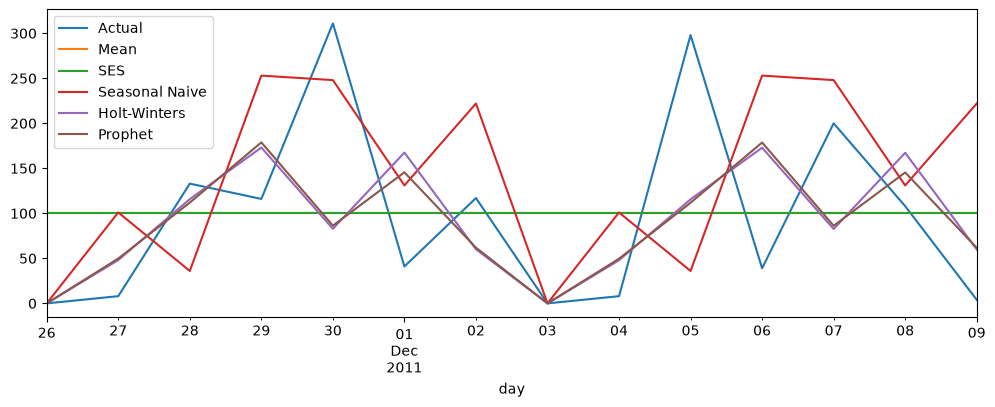

In [38]:
comparison = pd.DataFrame(index=test.index)

comparison["Actual"] = test
comparison["Mean"] = mean_sales
comparison["SES"] = ses_forecast
comparison["Seasonal Naive"] = seasonal_naive_forecast
comparison["Holt-Winters"] = hw_forecast_zero
comparison["Prophet"] = prophet_forecast_zero

comparison.plot(figsize=(12, 4))

In [39]:
prophet_full = pd.DataFrame({"ds": daily_sales.index, "y": daily_sales.tolist()})

final_model = Prophet().fit(prophet_full)

future_dates = final_model.make_future_dataframe(14, include_history=False)

final_result = final_model.predict(future_dates)

final_result["yhat"] = final_result["yhat"].clip(lower=0)

final_result["yhat"].sum()

23:48:22 - cmdstanpy - INFO - Chain [1] start processing
23:48:22 - cmdstanpy - INFO - Chain [1] done processing


np.float64(1279.145157806873)